# CelebA Attribute Recognition Dataset Preparation and EDA

The data is obatined from: https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html

The dataset is structued as follows:
``` text
CelebA:
|---img_align_celeba
|----|-------000001.jpg
|----|-------000002.jpg
|----|-------...
|---list_attr_celeba.csv
|---list_bbox_celeba.csv
|---list_eval_partition.csv
|---list_landmarks_align_celeba.csv

It will be transformed into an images folder and a labels.csv file.

In [1]:
import numpy as np, os, shutil, PIL.Image as Image, matplotlib.pyplot as plt, pandas as pd
os.chdir('..')

In [2]:
dataset_dir = os.path.join('data', 'datasets', 'attribute recognition', 'CelebA')
os.path.exists(dataset_dir)

True

In [4]:
old_images_dir = os.path.join(dataset_dir, 'img_align_celeba', 'img_align_celeba')
os.path.exists(old_images_dir)

True

In [5]:
attributes_file = pd.read_csv(os.path.join(dataset_dir, 'list_attr_celeba.csv'))

In [6]:
attributes_file.head()

,image_id,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
0,000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,...,-1,1,1,-1,1,-1,1,-1,-1,1
1,000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
2,000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,1
3,000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,...,-1,-1,1,-1,1,-1,1,1,-1,1
4,000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1


In [7]:
evaluation_partition_file = pd.read_csv(os.path.join(dataset_dir, 'list_eval_partition.csv'))

In [8]:
evaluation_partition_file.head()

,image_id,partition
0,000001.jpg,0
1,000002.jpg,0
2,000003.jpg,0
3,000004.jpg,0
4,000005.jpg,0


In [9]:
evaluation_partition_file['partition'] = evaluation_partition_file['partition'].replace(0, 'train')
evaluation_partition_file['partition'] = evaluation_partition_file['partition'].replace(1, 'validation')
evaluation_partition_file['partition'] = evaluation_partition_file['partition'].replace(2, 'test')
evaluation_partition_file.head()

,image_id,partition
0,000001.jpg,train
1,000002.jpg,train
2,000003.jpg,train
3,000004.jpg,train
4,000005.jpg,train


In [10]:
attributes_file['split'] = evaluation_partition_file['partition'].replace()
attributes_file = attributes_file.rename(columns = {'image_id' : 'filename'})
attributes_file.head()

/tmp/ipykernel_188459/1318638626.py:1: FutureWarning: Series.replace without 'value' and with non-dict-like 'to_replace' is deprecated and will raise in a future version. Explicitly specify the new values instead.
  attributes_file['split'] = evaluation_partition_file['partition'].replace()


,filename,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,...,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young,split
0,000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,...,1,1,-1,1,-1,1,-1,-1,1,train
1,000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,...,1,-1,-1,-1,-1,-1,-1,-1,1,train
2,000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,...,-1,-1,1,-1,-1,-1,-1,-1,1,train
3,000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,...,-1,1,-1,1,-1,1,1,-1,1,train
4,000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,1,-1,-1,1,train


In [11]:
attribute_groups = {
            'Whole' : ['Attractive', 'Blurry', 'Chubby', 'Heavy_Makeup', 'Oval_Face', 'Pale_Skin', 'Male', 'Young'],
            'Hair' : ['Bald', 'Bangs', 'Black_Hair', 'Blond_Hair', 'Brown_Hair', 'Gray_Hair', 'Receding_Hairline', 'Straight_Hair', 'Wavy_Hair', 'Wearing_Hat'],
            'Eyes' : ['Arched_Eyebrows', 'Bags_Under_Eyes', 'Bushy_Eyebrows', 'Eyeglasses', 'Narrow_Eyes'],
            'Nose' : ['Big_Nose', 'Pointy_Nose'],
            'Cheek' : ['High_Cheekbones', 'Rosy_Cheeks', 'Wearing_Earrings', 'Sideburns'],
            'Mouth' : ['5_o_Clock_Shadow', 'Big_Lips', 'Mouth_Slightly_Open', 'Mustache', 'Wearing_Lipstick', 'No_Beard', 'Smiling', 'Goatee'],
            'Neck' : ['Wearing_Necklace', 'Wearing_Necktie', 'Double_Chin']
        }

In [12]:
count = 0
for key, value in attribute_groups.items():
    print(len(value))
    count += len(value)
print(count)

8
10
5
2
4
8
3
40


In [13]:
ordered_attributes = []
for key, group in attribute_groups.items():
    for attribute in group:
        ordered_attributes.append(attribute)

In [14]:
attributes_file = attributes_file.loc[:, ['filename', *ordered_attributes, 'split']]

In [15]:
attributes_file

,filename,Attractive,Blurry,Chubby,Heavy_Makeup,Oval_Face,Pale_Skin,Male,Young,Bald,...,Mouth_Slightly_Open,Mustache,Wearing_Lipstick,No_Beard,Smiling,Goatee,Wearing_Necklace,Wearing_Necktie,Double_Chin,split
0,000001.jpg,1,-1,-1,1,-1,-1,-1,1,-1,...,1,-1,1,1,1,-1,-1,-1,-1,train
1,000002.jpg,-1,-1,-1,-1,-1,-1,-1,1,-1,...,1,-1,-1,1,1,-1,-1,-1,-1,train
2,000003.jpg,-1,1,-1,-1,-1,-1,1,1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,train
3,000004.jpg,1,-1,-1,-1,-1,-1,-1,1,-1,...,-1,-1,1,1,-1,-1,1,-1,-1,train
4,000005.jpg,1,-1,-1,1,-1,-1,-1,1,-1,...,-1,-1,1,1,-1,-1,-1,-1,-1,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202594,202595.jpg,1,-1,-1,-1,-1,-1,-1,1,-1,...,-1,-1,1,1,-1,-1,-1,-1,-1,test
202595,202596.jpg,-1,-1,-1,-1,-1,1,1,1,-1,...,1,-1,-1,1,1,-1,-1,-1,-1,test
202596,202597.jpg,-1,-1,-1,-1,-1,-1,1,1,-1,...,1,-1,-1,1,1,-1,-1,-1,-1,test
202597,202598.jpg,1,-1,-1,1,1,-1,-1,1,-1,...,-1,-1,1,1,1,-1,-1,-1,-1,test


In [16]:
attributes_file.to_csv(
    os.path.join(dataset_dir, 'labels.csv'),
    index = False,
)

In [17]:
len(attributes_file.columns)

42

## EDA

In [18]:
labels_file = pd.read_csv(os.path.join(dataset_dir, 'labels.csv'))

In [19]:
np.unique(labels_file['split'], return_counts = True)

(array(['test', 'train', 'validation'], dtype=object),
 array([ 19962, 162770,  19867]))

In [20]:
162769 + 19867

182636

In [21]:
for column in labels_file.columns:
    print(column)

filename
Attractive
Blurry
Chubby
Heavy_Makeup
Oval_Face
Pale_Skin
Male
Young
Bald
Bangs
Black_Hair
Blond_Hair
Brown_Hair
Gray_Hair
Receding_Hairline
Straight_Hair
Wavy_Hair
Wearing_Hat
Arched_Eyebrows
Bags_Under_Eyes
Bushy_Eyebrows
Eyeglasses
Narrow_Eyes
Big_Nose
Pointy_Nose
High_Cheekbones
Rosy_Cheeks
Wearing_Earrings
Sideburns
5_o_Clock_Shadow
Big_Lips
Mouth_Slightly_Open
Mustache
Wearing_Lipstick
No_Beard
Smiling
Goatee
Wearing_Necklace
Wearing_Necktie
Double_Chin
split


In [22]:
(labels_file['split'] == 'train').sum(), (labels_file['split'] == 'test').sum(), (labels_file['split'] == 'validation').sum()

(np.int64(162770), np.int64(19962), np.int64(19867))

In [23]:
labels_file.head()

,filename,Attractive,Blurry,Chubby,Heavy_Makeup,Oval_Face,Pale_Skin,Male,Young,Bald,...,Mouth_Slightly_Open,Mustache,Wearing_Lipstick,No_Beard,Smiling,Goatee,Wearing_Necklace,Wearing_Necktie,Double_Chin,split
0,000001.jpg,1,-1,-1,1,-1,-1,-1,1,-1,...,1,-1,1,1,1,-1,-1,-1,-1,train
1,000002.jpg,-1,-1,-1,-1,-1,-1,-1,1,-1,...,1,-1,-1,1,1,-1,-1,-1,-1,train
2,000003.jpg,-1,1,-1,-1,-1,-1,1,1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,train
3,000004.jpg,1,-1,-1,-1,-1,-1,-1,1,-1,...,-1,-1,1,1,-1,-1,1,-1,-1,train
4,000005.jpg,1,-1,-1,1,-1,-1,-1,1,-1,...,-1,-1,1,1,-1,-1,-1,-1,-1,train


In [24]:
counts = {}
columns = list(labels_file.columns)[1:-1] # only keep the attributes
for column in columns:
    values = labels_file[column]
    values.replace(-1, 0, inplace = True)
    counts[column] = sum(values)

In [25]:
sorted_index = np.argsort(list(counts.values()))
x = [key for key in counts.keys()]
y = [value for value in counts.values()]
x = [x[i] for i in sorted_index]
y = [y[i] for i in sorted_index]


In [26]:
figures_path = os.path.join('data', 'figures', 'Attribute Recognition', 'CelebA')
os.makedirs(figures_path, exist_ok = True)

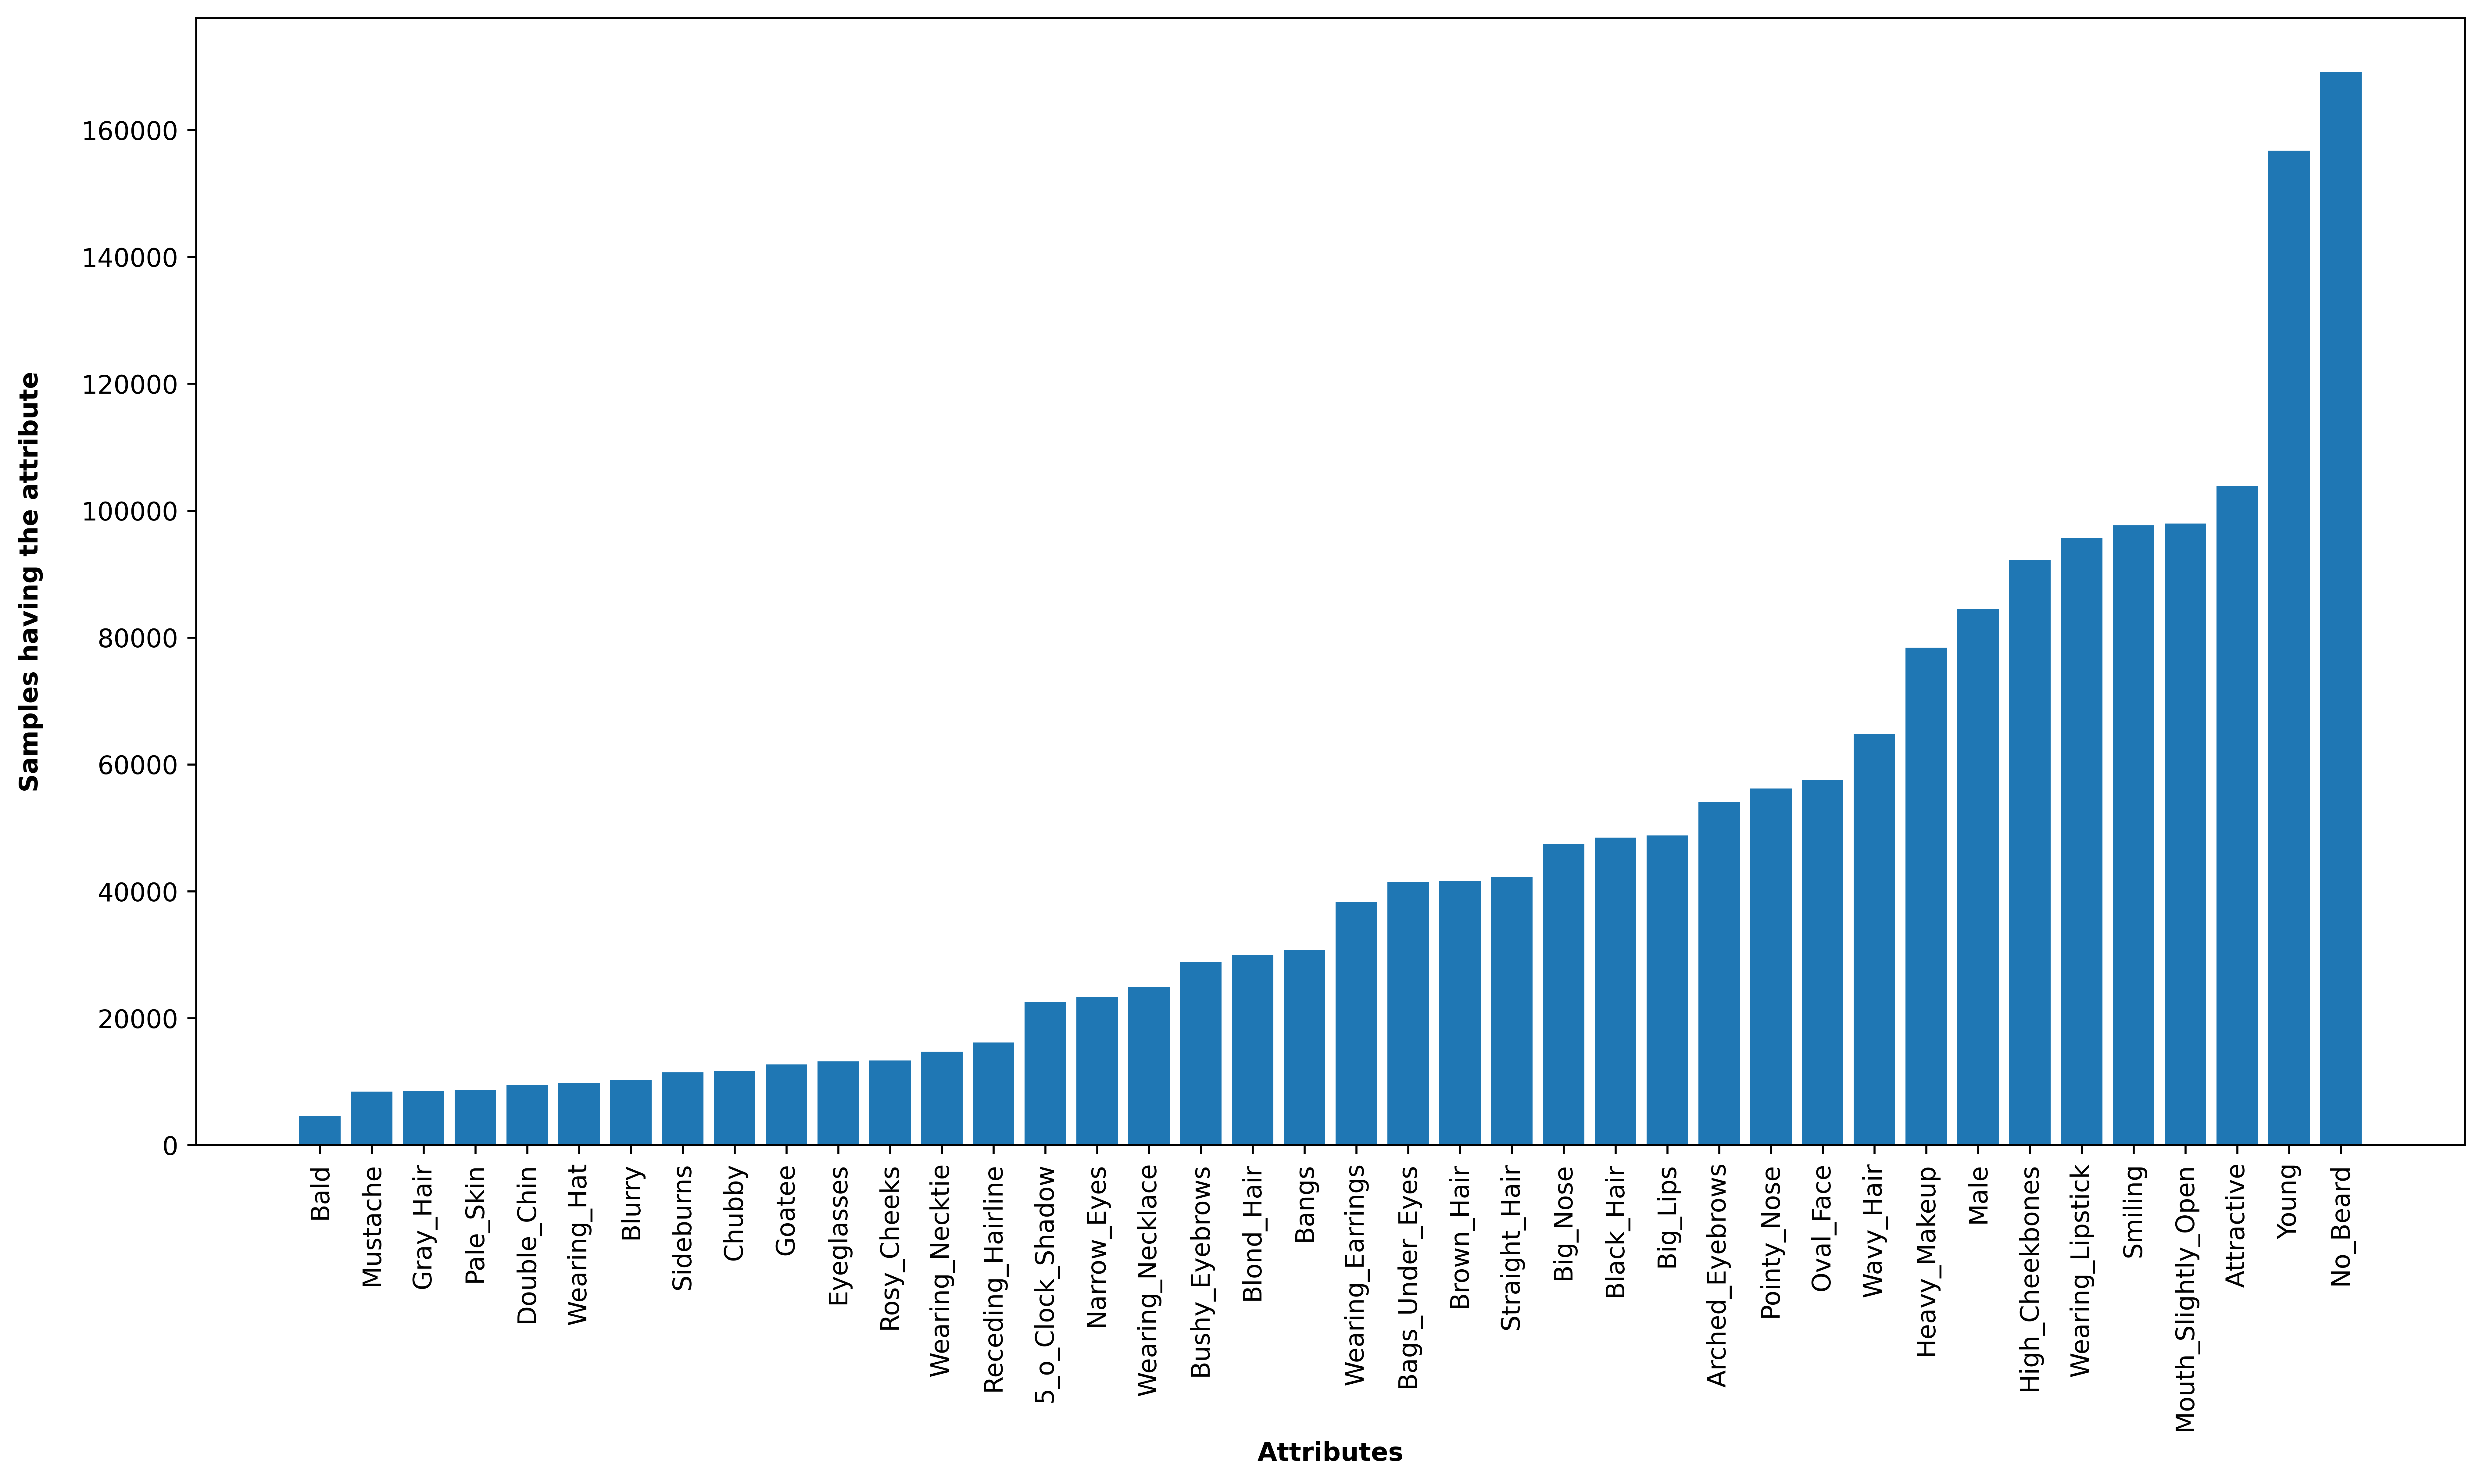

In [27]:
plt.figure(figsize = (16, 8), dpi = 600)
plt.bar(x, y)
plt.xticks(rotation = 90)
plt.xlabel('Attributes', fontweight = 'bold')
plt.ylabel('Samples having the attribute', labelpad = 15, fontweight = 'bold')
plt.savefig(
    os.path.join(figures_path, 'The distribution of attributes in CelebA'),
    bbox_inches = 'tight'
)
plt.show()

In [28]:
attributes_list = np.array(list(labels_file.columns)[1:-1])

In [45]:
from torchvision.transforms import v2
import torch
attribute_recognition_transform = v2.Compose([
    v2.ToImage(),
    
    # 1. Pad the width to make the image a perfect 218x218 square
    # Format: (left, top, right, bottom)
    # Using 'edge' or 'reflect' prevents harsh black borders
    v2.Pad((20, 0, 20, 0), padding_mode='edge'), 
    
    # 2. Safely resize the perfect square down to the model's required input size
    v2.Resize((112, 112), antialias=True),
    
    # 3. Apply your standard augmentations (ColorJitter, RandomHorizontalFlip, etc.)
    # ...
    
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

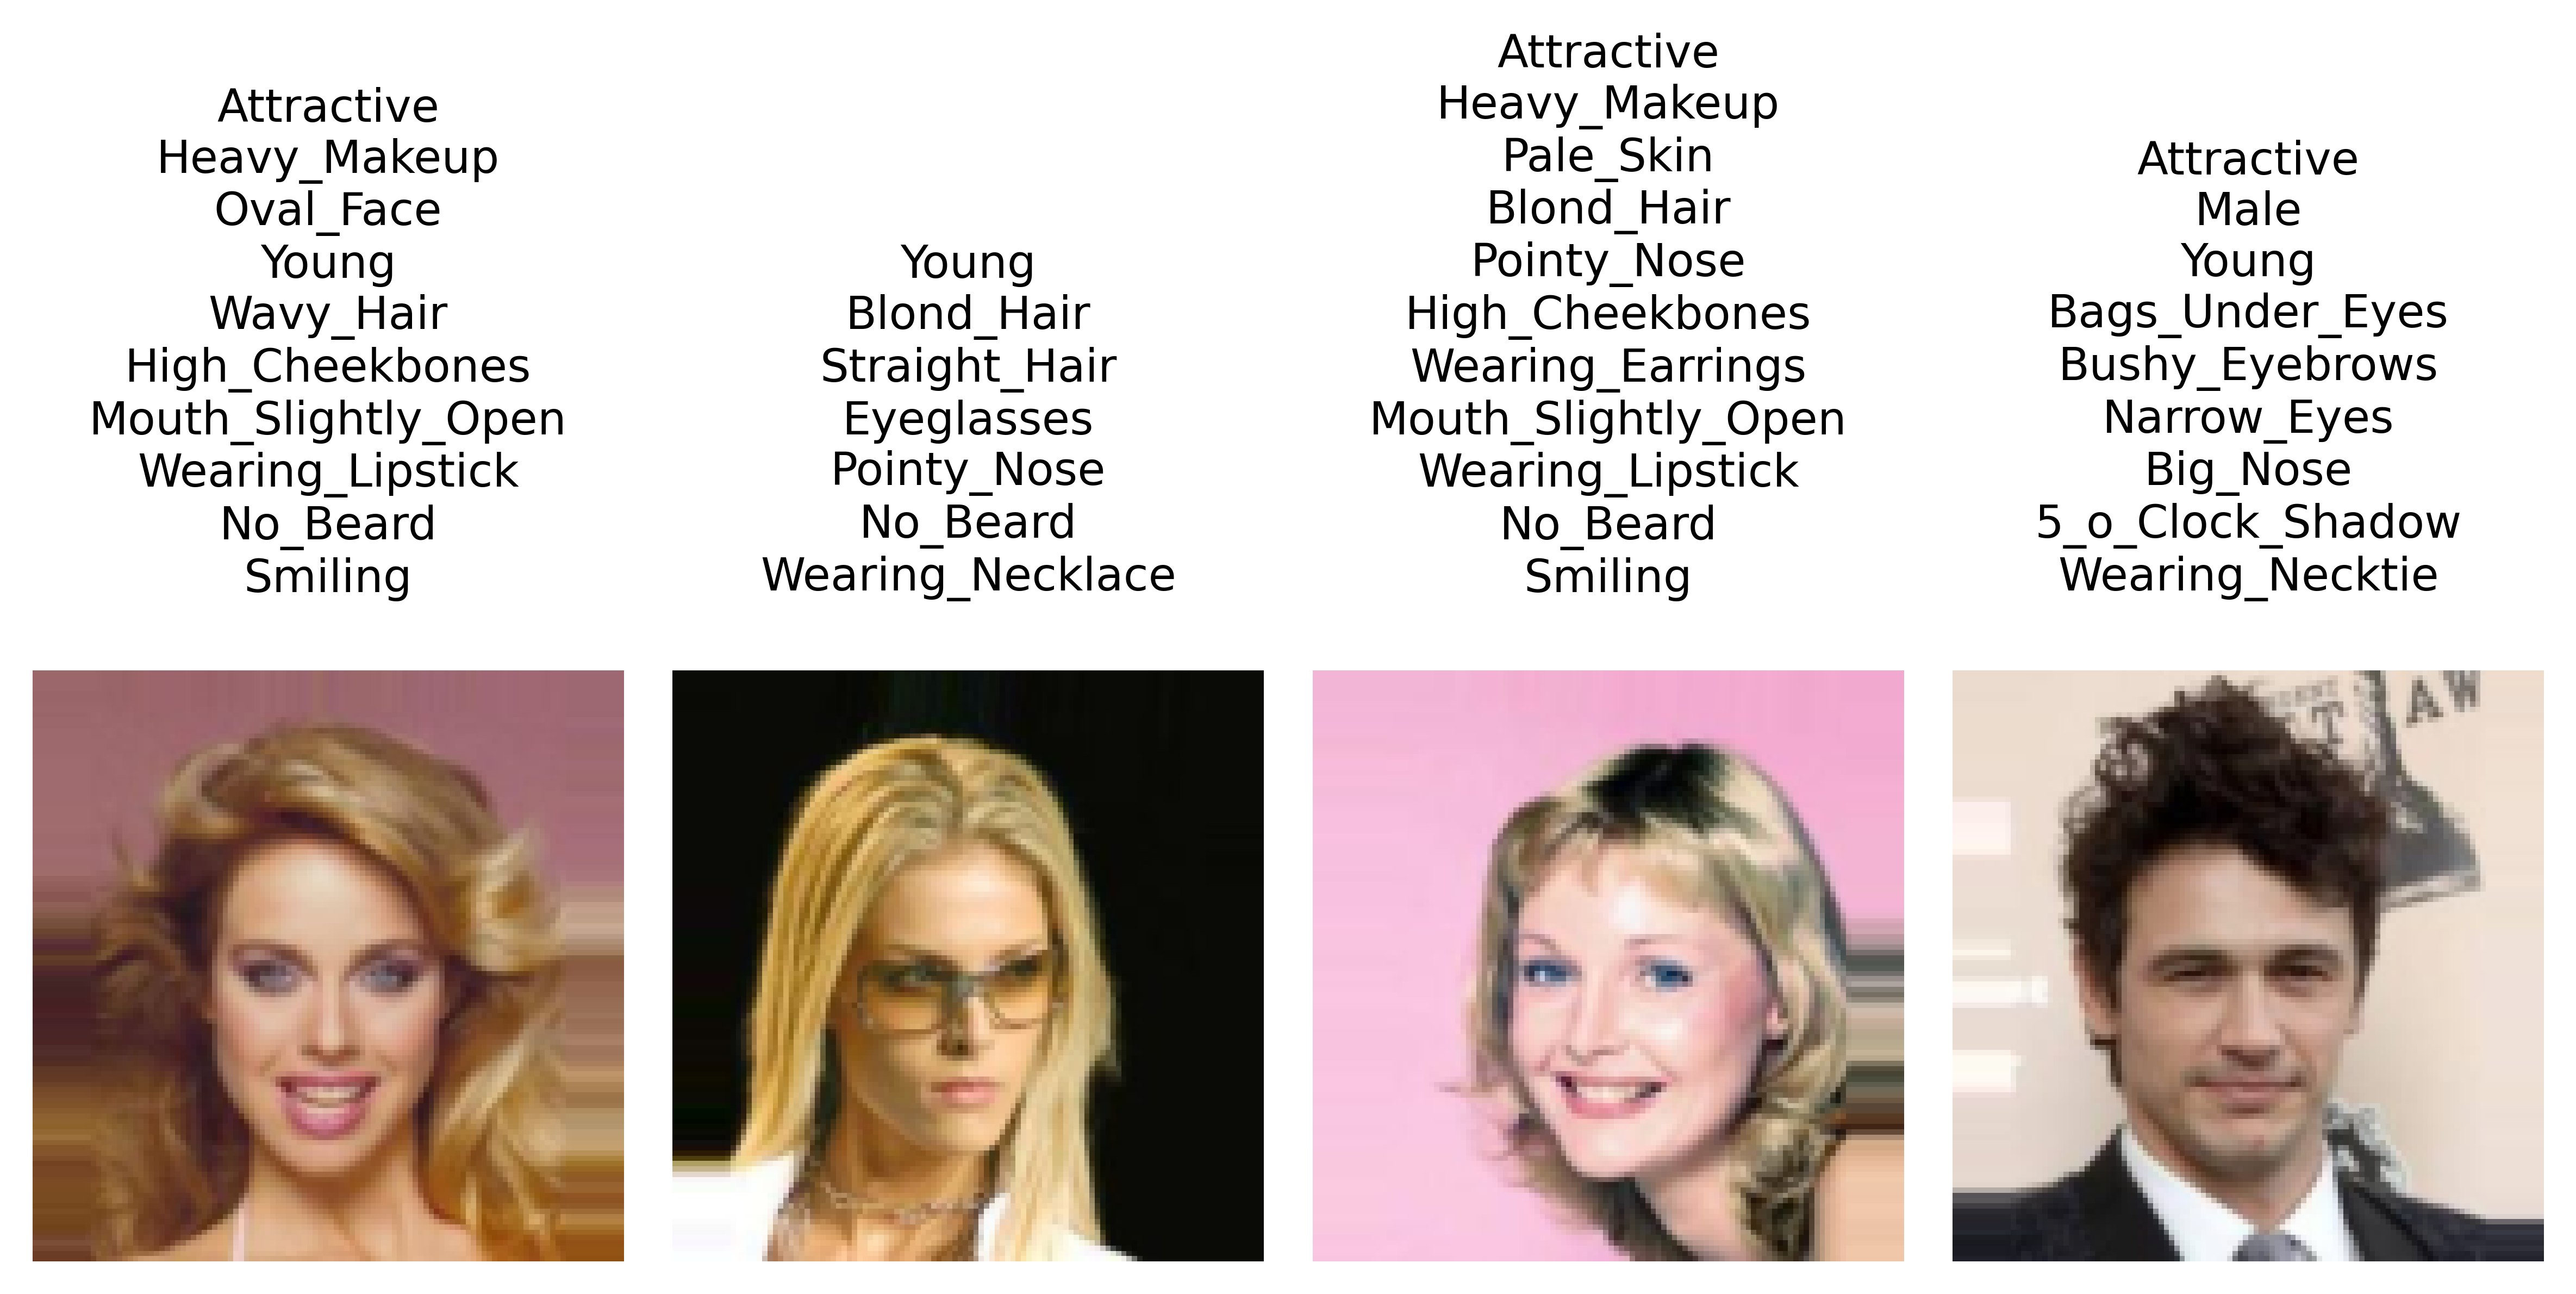

In [46]:
plt.figure(figsize = (8, 8), dpi = 600)
for i in range(4):
    image_index = np.random.randint(low = 0, high = len(labels_file))
    image_name = labels_file['filename'].iloc[image_index]
    attributes_indices = np.array(list(labels_file.iloc[image_index])[1:-1])
    attributes = attributes_list[attributes_indices == 1]
    image = Image.open(os.path.join(old_images_dir, image_name))
    image = attribute_recognition_transform(image)
    image = image*0.5 + 0.5
    plt.subplot(1, 4, i+1)
    title_string = ''
    for attribute in attributes:
        title_string += attribute + '\n'
    plt.title(title_string, fontsize = 10)
    plt.imshow(image.permute(1, 2, 0))
    plt.axis('off')
    plt.tight_layout()
plt.savefig(
    os.path.join(figures_path, 'Sample images from CelebA'),
    bbox_inches = 'tight'
)
plt.show()